# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhammad Fasya Atthaya Rosyada | 5054251006 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.
df = pd.read_csv("Mall_Customers.csv")

display(df.head())
print("Dimensi Data:", df.shape)
print("\nTipe Data:\n", df.dtypes)
print("\nStatistik Deskriptif:\n", df.describe())
print("\nMissing Value:\n", df.isnull().sum())
print("\nBaris Duplikat:", df.duplicated().sum())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dimensi Data: (200, 5)

Tipe Data:
 CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Statistik Deskriptif:
        CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000

Missing Value:
 CustomerID                0
Gender                    0
Age                       0

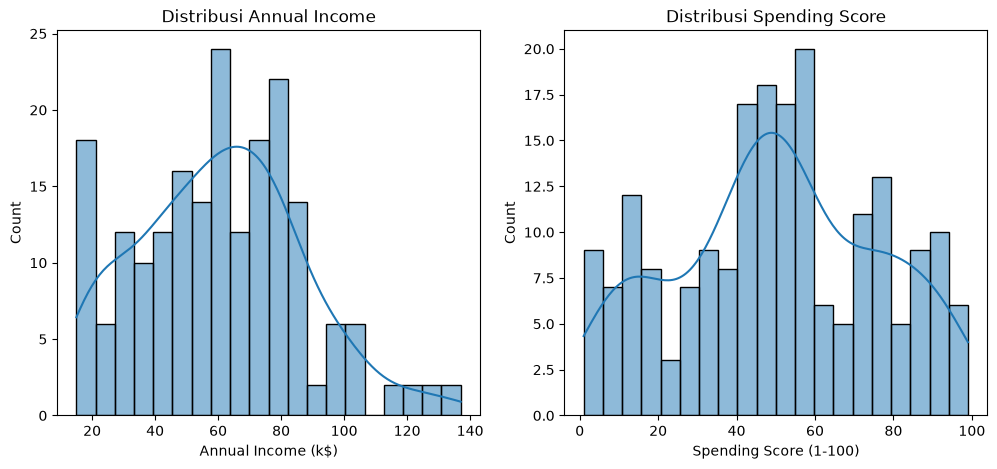

In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Annual Income (k$)'], kde=True, bins=20)
plt.title('Distribusi Annual Income')

plt.subplot(1, 2, 2)
sns.histplot(df['Spending Score (1-100)'], kde=True, bins=20)
plt.title('Distribusi Spending Score')
plt.show()

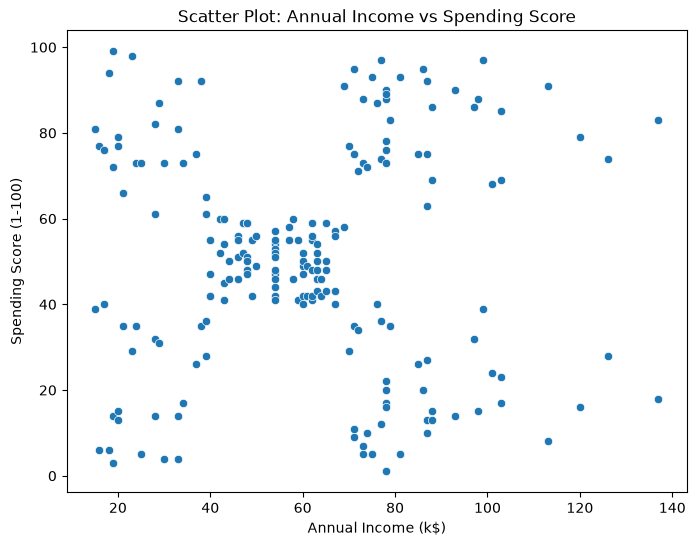

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)')
plt.title('Scatter Plot: Annual Income vs Spending Score')
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat? 
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

Jawaban:
- Tidak ada missing value (0) dan tidak ada baris yang duplikat (0).
- Rentang pendapatan tahunan (Annual Income) berkisar antara 15k hingga 137k dolar, dengan rata-rata sekitar 60.5k dolar. Spending score berada pada rentang 1 hingga 99 dengan rata-rata sekitar 50.
- Ya, dari scatter plot keliatan adanya 5 kelompok (cluster) utama pelanggan yang terpisah satu sama lain.

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

display(X_scaled.head())
print("\nStatistik Deskriptif X_scaled:\n", X_scaled.describe().round(2))

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Statistik Deskriptif X_scaled:
        Annual Income (k$)  Spending Score (1-100)
count              200.00                  200.00
mean                -0.00                   -0.00
std                  1.00                    1.00
min                 -1.74                   -1.91
25%                 -0.73                   -0.60
50%                  0.04                   -0.01
75%                  0.67                    0.89
max                  2.92                    1.89


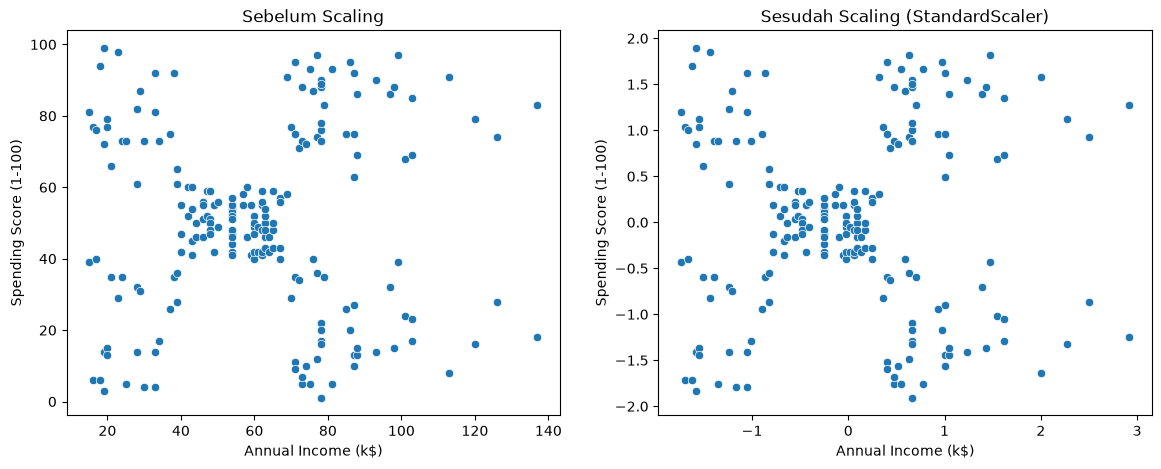

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=X, x='Annual Income (k$)', y='Spending Score (1-100)', ax=axes[0])
axes[0].set_title('Sebelum Scaling')

sns.scatterplot(data=X_scaled, x='Annual Income (k$)', y='Spending Score (1-100)', ax=axes[1])
axes[1].set_title('Sesudah Scaling (StandardScaler)')
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Fitur Annual Income dan Spending Score digunakan karena mendeskripsikan daya beli dan perilaku konsumtif pelanggan. CustomerID tidak digunakan karena hanya berupa nomor urut identitas unik yang tidak memiliki nilai matematis atau perilaku.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).
unique_labels, counts = np.unique(labels_dbscan, return_counts=True)
n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = list(labels_dbscan).count(-1)

print("Distribusi label DBSCAN:")
for label, count in zip(unique_labels, counts):
    print(f"Cluster {label}: {count} anggota")
print(f"\nJumlah Cluster: {n_clusters}")
print(f"Jumlah Titik Noise: {n_noise}")

Distribusi label DBSCAN:
Cluster -1: 35 anggota
Cluster 0: 12 anggota
Cluster 1: 5 anggota
Cluster 2: 7 anggota
Cluster 3: 88 anggota
Cluster 4: 30 anggota
Cluster 5: 14 anggota
Cluster 6: 9 anggota

Jumlah Cluster: 7
Jumlah Titik Noise: 35


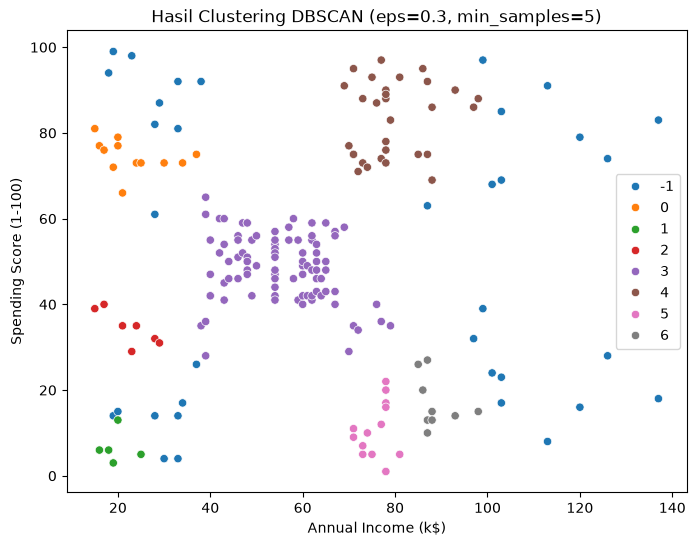

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X['Annual Income (k$)'], y=X['Spending Score (1-100)'], 
                hue=labels_dbscan, palette='tab10', legend='full')
plt.title(f'Hasil Clustering DBSCAN (eps=0.3, min_samples=5)')
plt.show()

In [14]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.
eps_values = [0.2, 0.3, 0.4, 0.5]
min_samples_values = [3, 5, 7, 10]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X_scaled)
        
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        
        valid_idx = labels != -1
        if n_clusters >= 2 and np.sum(valid_idx) > n_clusters:
            sil_score = silhouette_score(X_scaled.values[valid_idx], labels[valid_idx])
        else:
            sil_score = None
            
        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Jumlah Cluster': n_clusters,
            'Jumlah Noise': n_noise,
            'Silhouette Score': sil_score
        })

df_dbscan_summary = pd.DataFrame(results)
display(df_dbscan_summary)

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Silhouette Score
0,0.2,3,13,44,0.469713
1,0.2,5,7,77,0.585613
2,0.2,7,4,100,0.609411
3,0.2,10,1,129,NaN
4,0.3,3,9,14,0.472040
5,0.3,5,7,35,0.524328
6,0.3,7,4,72,0.645159
7,0.3,10,4,88,0.607301
8,0.4,3,4,10,0.395381
9,0.4,5,4,15,0.478059


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

Jawaban:
- Memperbesar eps akan membuat semakin banyak titik yang terhubung menjadi satu cluster, menurunkan jumlah cluster, dan mengurangi jumlah noise. Jika terlalu besar, semua data akan bergabung jadi satu cluster.
- Memperbesar min_samples membuat syarat sebuah titik untuk menjadi core point semakin ketat, sehingga jumlah noise akan meningkat drastis.
- Kombinasi eps yang sangat kecil dan min_samples yang besar (contoh: eps=0.2 dan min_samples=10) menghasilkan 129 titik noise. Sedangkan kombinasi eps yang besar dengan min_samples yang kecil (contoh: eps=0.5 dan min_samples=3) menghasilka hanya 2 cluster.


# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [11]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

In [12]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
unique_labels_b, counts_b = np.unique(labels_birch, return_counts=True)
print("Distribusi label BIRCH:")
for label, count in zip(unique_labels_b, counts_b):
    print(f"Cluster {label}: {count} anggota")
print(f"Jumlah Cluster: {len(unique_labels_b)}")

Distribusi label BIRCH:
Cluster 0: 36 anggota
Cluster 1: 109 anggota
Cluster 2: 8 anggota
Cluster 3: 25 anggota
Cluster 4: 22 anggota
Jumlah Cluster: 5


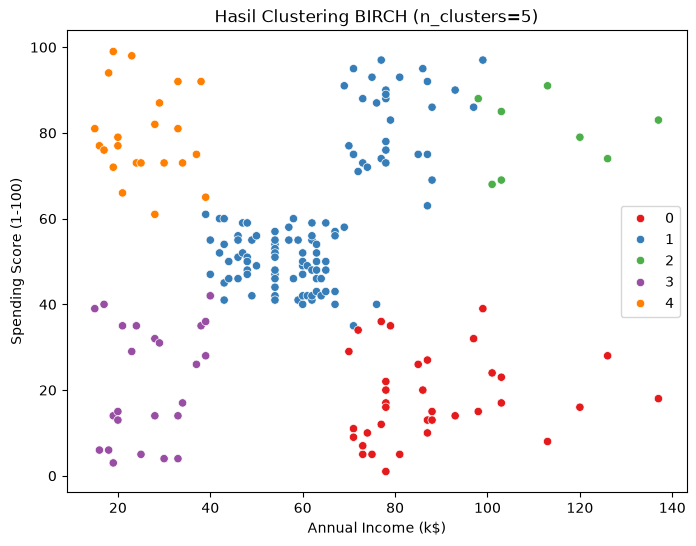

In [13]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X['Annual Income (k$)'], y=X['Spending Score (1-100)'], 
                hue=labels_birch, palette='Set1', legend='full')
plt.title('Hasil Clustering BIRCH (n_clusters=5)')
plt.show()

In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.
import warnings
warnings.filterwarnings('ignore')

thresholds = [0.3, 0.5, 0.7, 1.0]
results_birch = []

for t in thresholds:
    birch = Birch(threshold=t, n_clusters=5)
    labels = birch.fit_predict(X_scaled)
    
    n_clusters = len(set(labels))
    
    if n_clusters > 1:
        sil_score = silhouette_score(X_scaled, labels)
    else:
        sil_score = None
        
    results_birch.append({
        'Threshold': t,
        'Jumlah Cluster Akhir': n_clusters,
        'Silhouette Score': sil_score
    })

df_birch_summary = pd.DataFrame(results_birch)
display(df_birch_summary)

,Threshold,Jumlah Cluster Akhir,Silhouette Score
0,0.3,5,0.478062
1,0.5,5,0.414450
2,0.7,5,0.420676
3,1.0,4,0.388557


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

Jawaban:
- Semakin besar nilai threshold, semakin besar pula radius yang diizinkan untuk setiap subcluster di dalam struktur pohon sehingga lebih banyak titik data yang digabungkan ke dalam subcluster yang sama.
- DBSCAN akan mendeteksi titik yang jauh dari kelompok utama sebagai noise (-1) dan mengabaikannya dari klaster mana pun. Sebaliknya, BIRCH tidak memiliki konsep noise dan akan tetap memasukkan titik yang jauh ke dalam subcluster terdekat atau membuatnya menjadi subcluster sendiri.
- Ya. Saat n_clusters ditentukan, BIRCH melakukan pengelompokan hierarkis di tahap akhir untuk menggabungkan banyak subcluster kecil menjadi persis sejumlah n_clusters yang diminta. Namun, jika threshold terlalu besar sejak awal, subcluster yang terbentuk mungkin sudah lebih sedikit dari n_clusters, sehingga algoritma terpaksa menghasilkan cluster akhir kurang dari yang diminta.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)

In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.
probs = gmm.predict_proba(X_scaled)
print("Distribusi cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())
print("\n5 Baris pertama probabilitas keanggotaan:")
print(pd.DataFrame(probs, columns=[f'C{i}' for i in range(5)]).head())

Distribusi cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

5 Baris pertama probabilitas keanggotaan:
             C0            C1            C2            C3        C4
0  1.576897e-05  1.880092e-08  9.520312e-04  5.200131e-08  0.999032
1  1.627762e-05  1.895968e-04  9.997902e-01  4.210134e-23  0.000004
2  2.213394e-19  9.526157e-19  1.225495e-12  1.862233e-04  0.999814
3  1.054448e-04  1.800877e-04  9.996937e-01  3.793901e-21  0.000021
4  6.473014e-05  3.842732e-08  1.556695e-03  4.757227e-08  0.998378


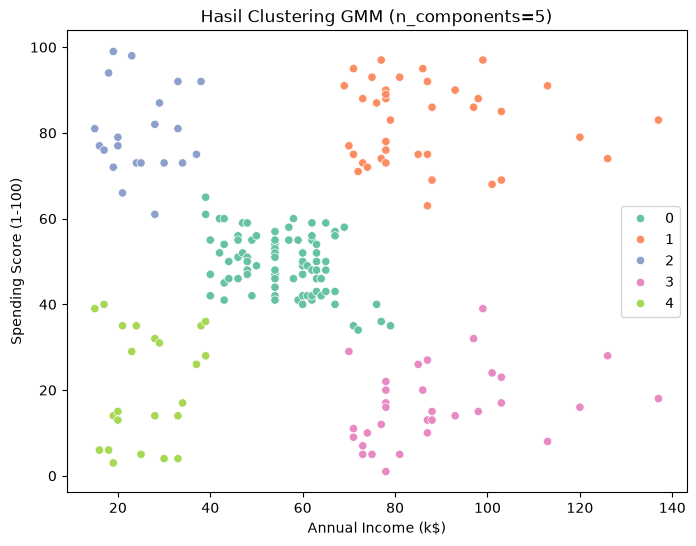

In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X['Annual Income (k$)'], y=X['Spending Score (1-100)'], 
                hue=labels_gmm, palette='Set2', legend='full')
plt.title('Hasil Clustering GMM (n_components=5)')
plt.show()

In [ ]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.
components_range = range(2, 9)
results_gmm = []

for n in components_range:
    # Latih model
    gmm = GaussianMixture(n_components=n, covariance_type='full', random_state=42)
    labels = gmm.fit_predict(X_scaled)
    
    # Hitung metrik
    sil_score = silhouette_score(X_scaled, labels)
    bic_score = gmm.bic(X_scaled)
    
    results_gmm.append({
        'n_components': n,
        'Silhouette Score': sil_score,
        'BIC': bic_score
    })

df_gmm_summary = pd.DataFrame(results_gmm)
display(df_gmm_summary)

,n_components,Silhouette Score,BIC
0,2,0.379082,1153.904655
1,3,0.430190,1151.718274
2,4,0.413392,1103.790149
3,5,0.553689,1058.652252
4,6,0.516982,1074.682807
5,7,0.509057,1087.328517
6,8,0.430210,1102.370701


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

Jawaban:
- GMM menggunakan pendekatan soft clustering, yang berarti setiap titik data tidak langsung dipaksa masuk ke satu klaster secara mutlak, melainkan memiliki nilai probabilitas (peluang) untuk setiap komponen/klaster.
- Mengubah asumsi jumlah sub-distribusi yang ada di dalam dataset. Jika nilainya kurang tepat, hasil pemodelan tidak akan akurat.
- Karena Expectation-Maximization (EM) pada GMM adalah algoritma optimasi parametrik. Algoritma ini membutuhkan nilai awal k untuk menginisialisasi tebakan awal jumlah pusat (mean) dan matriks kovarians, sebelum ia secara iteratif menyesuaikan distribusinya agar cocok dengan data.
- Ya, pada dataset ini keduanya sangat selaras. Pada saat n_components = 5, GMM menghasilkan kombinasi terbaik dengan Silhouette Score tertinggi (0.553) dan nilai BIC terendah (1058.65).

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.
def evaluate_clustering(X, labels):
    valid_idx = labels != -1
    if len(set(labels[valid_idx])) > 1:
        sil = silhouette_score(X[valid_idx], labels[valid_idx])
        db = davies_bouldin_score(X[valid_idx], labels[valid_idx])
        ch = calinski_harabasz_score(X[valid_idx], labels[valid_idx])
        return sil, db, ch
    return None, None, None

In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.
results = []
for name, labels in zip(["DBSCAN", "BIRCH", "GMM"], [labels_dbscan, labels_birch, labels_gmm]):
    sil, db, ch = evaluate_clustering(X_scaled.values, labels)
    n_clus = len(set(labels)) - (1 if -1 in labels else 0)
    noise = list(labels).count(-1) if name == "DBSCAN" else 0
    results.append([name, n_clus, noise, sil, db, ch])

df_eval = pd.DataFrame(results, columns=["Model", "Clusters", "Noise", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"])
display(df_eval)

,Model,Clusters,Noise,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,DBSCAN,7,35,0.524328,0.579955,185.575811
1,BIRCH,5,0,0.414450,0.697938,125.948605
2,GMM,5,0,0.553689,0.576010,244.940197


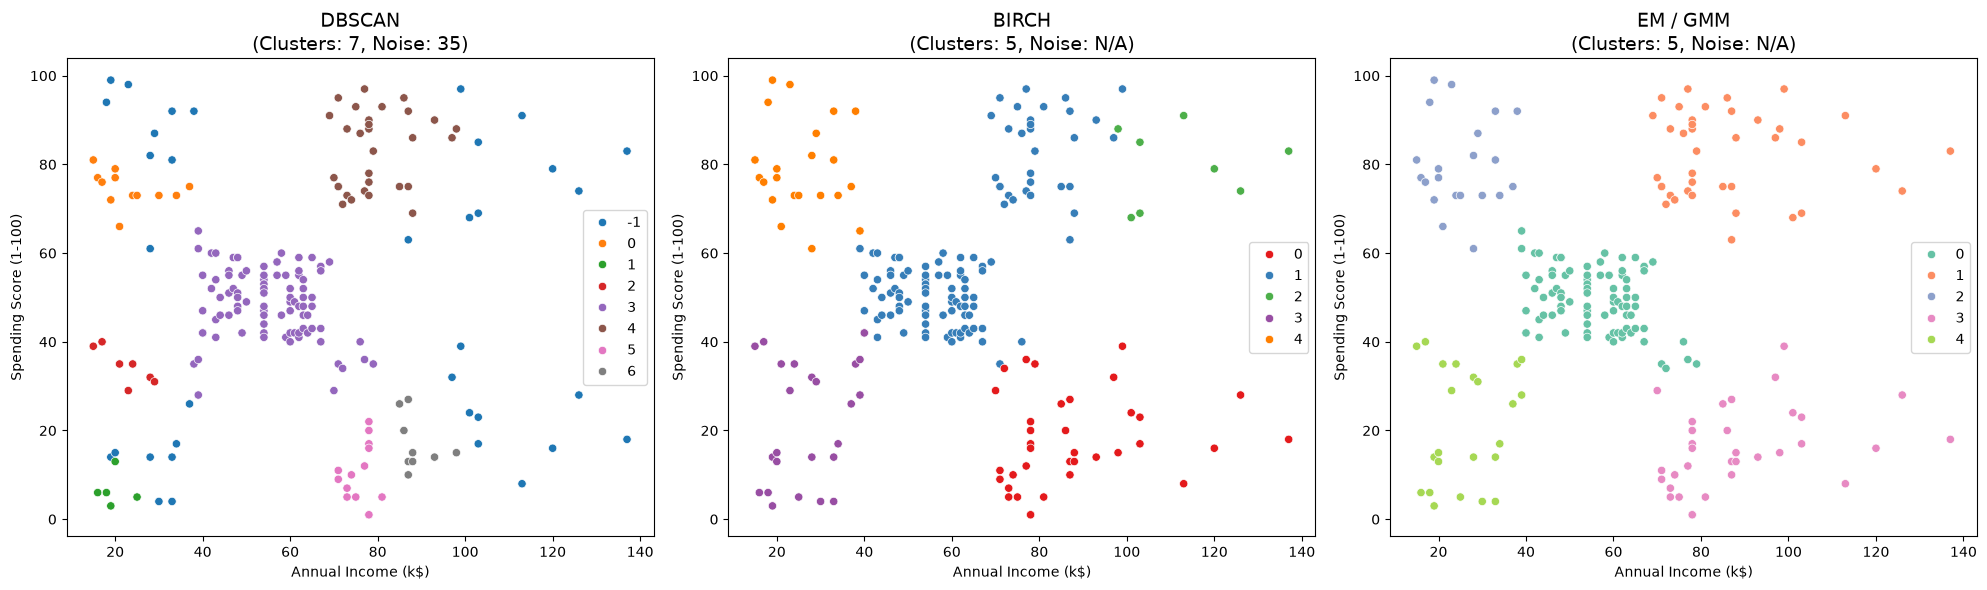

In [23]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = list(labels_dbscan).count(-1)

n_clusters_birch = len(set(labels_birch))
n_clusters_gmm = len(set(labels_gmm))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.scatterplot(x=X['Annual Income (k$)'], y=X['Spending Score (1-100)'], 
                hue=labels_dbscan, palette='tab10', legend='full', ax=axes[0])
axes[0].set_title(f'DBSCAN\n(Clusters: {n_clusters_dbscan}, Noise: {n_noise_dbscan})', fontsize=14)

sns.scatterplot(x=X['Annual Income (k$)'], y=X['Spending Score (1-100)'], 
                hue=labels_birch, palette='Set1', legend='full', ax=axes[1])
axes[1].set_title(f'BIRCH\n(Clusters: {n_clusters_birch}, Noise: N/A)', fontsize=14)

sns.scatterplot(x=X['Annual Income (k$)'], y=X['Spending Score (1-100)'], 
                hue=labels_gmm, palette='Set2', legend='full', ax=axes[2])
axes[2].set_title(f'EM / GMM\n(Clusters: {n_clusters_gmm}, Noise: N/A)', fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.
df['DBSCAN_Label'] = labels_dbscan
df['BIRCH_Label'] = labels_birch
df['GMM_Label'] = labels_gmm

print("=== DBSCAN Profile ===")
dbscan_profile = df.groupby('DBSCAN_Label')[['Annual Income (k$)', 'Spending Score (1-100)']].agg(['count', 'mean', 'median'])
display(dbscan_profile.round(2))

print("\n=== BIRCH Profile ===")
birch_profile = df.groupby('BIRCH_Label')[['Annual Income (k$)', 'Spending Score (1-100)']].agg(['count', 'mean', 'median'])
display(birch_profile.round(2))

print("\n=== GMM Profile ===")
gmm_profile = df.groupby('GMM_Label')[['Annual Income (k$)', 'Spending Score (1-100)']].agg(['count', 'mean', 'median'])
display(gmm_profile.round(2))

=== DBSCAN Profile ===


Annual Income (k$)               Spending Score (1-100)         \
                          count   mean median                  count   mean   
DBSCAN_Label                                                                  
-1                           35  70.60   87.0                     35  51.66   
 0                           12  23.17   20.5                     12  74.58   
 1                            5  19.60   19.0                      5   6.60   
 2                            7  22.43   23.0                      7  34.43   
 3                           88  55.23   54.0                     88  48.58   
 4                           30  79.53   78.0                     30  83.13   
 5                           14  75.93   77.5                     14  10.07   
 6                            9  88.78   87.0                      9  17.00   

                     
             median  
DBSCAN_Label         
-1             61.0  
 0             74.0  
 1              6.0  
 2             35.0  
 3             49.0  
 4             86.0  
 5              9.5  
 6             15.0


=== BIRCH Profile ===


Annual Income (k$)                Spending Score (1-100)         \
                         count    mean median                  count   mean   
BIRCH_Label                                                                   
0                           36   87.75   83.0                     36  17.58   
1                          109   62.39   62.0                    109  59.26   
2                            8  112.62  108.0                      8  79.62   
3                           25   27.40   28.0                     25  22.60   
4                           22   25.73   24.5                     22  79.36   

                    
            median  
BIRCH_Label         
0             16.0  
1             55.0  
2             81.0  
3             26.0  
4             77.0


=== GMM Profile ===


Annual Income (k$)               Spending Score (1-100)         \
                       count   mean median                  count   mean   
GMM_Label                                                                  
0                         84  55.64   55.5                     84  49.37   
1                         39  86.54   79.0                     39  82.13   
2                         21  25.10   24.0                     21  80.05   
3                         33  88.82   86.0                     33  16.00   
4                         23  26.30   25.0                     23  20.91   

                  
          median  
GMM_Label         
0           49.5  
1           83.0  
2           77.0  
3           15.0  
4           17.0

### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak|Ya | Ya|
| Dapat memberi label noise secara eksplisit? |Ya |Tidak |Tidak |
| Parameter yang paling memengaruhi hasil | eps, min_cluster|threshold, n_clusters |n_components, covariance_type |
| Bentuk cluster yang dapat dimodelkan |Arbitrer |Sperikal |Elips |
| Kelebihan | Menemukan cluster beraneka bentuk|Cepat & efisien untuk data skala besar |Menghasilkan probabilitas |
| Kekurangan |Susah mengatur parameter jika density data bervariasi |Kurang bagus untuk cluster yang bentuknya non-sperikal | Rawan terjebak local optima|

# 7. Analisis

1. **Pentingnya Feature Scaling**: Fitur perlu disamakan skalanya (di-scaling) karena algoritma clustering seperti DBSCAN dan BIRCH sangat bergantung pada perhitungan metrik jarak (seperti jarak *Euclidean*). Pada dataset ini, `Annual Income` berada dalam rentang ribuan dolar (meski tertulis 15–137k), sedangkan `Spending Score` hanya memiliki rentang 1–100. Tanpa proses scaling, fitur dengan nilai nominal besar akan mendominasi dan mengacaukan perhitungan jarak antar-titik, sehingga algoritma menjadi bias terhadap satu fitur saja.

2. **Pengaruh Parameter DBSCAN**:
   - **`eps` (Epsilon)**: Memperbesar `eps` akan memperluas jangkauan pencarian tetangga terdekat. Hal ini membuat semakin banyak titik bergabung ke dalam cluster yang sama, yang pada akhirnya menurunkan jumlah total cluster dan meminimalkan titik data yang terbuang sebagai *noise*.
   - **`min_samples`**: Memperbesar parameter ini memperketat syarat sebuah titik untuk menjadi pusat kepadatan (*core point*). Akibatnya, titik yang letaknya agak menyebar akan gagal memenuhi syarat, menyebabkan lonjakan jumlah *noise* dan penurunan jumlah cluster.

3. **Pengaruh Parameter BIRCH**:
   - **`threshold`**: Parameter ini membatasi seberapa jauh titik data bisa bergabung ke dalam satu *subcluster* (simpul) pada pohon struktur. Semakin besar angkanya, algoritma menjadi semakin toleran terhadap jarak yang jauh, sehingga titik-titik data digabungkan ke dalam jumlah *subcluster* alami yang jauh lebih sedikit.
   - **`n_clusters`**: Saat diatur (misalnya 5), BIRCH menambahkan tahap akhir berupa *agglomerative clustering* untuk memadatkan *subclusters* menjadi tepat sejumlah klaster yang diminta. Namun, jika parameter `threshold` terlalu besar di awal (misal 1.0) sehingga *subcluster* yang terbentuk hanya 4, tahap akhir tidak akan bisa menambahkannya kembali menjadi 5.

4. **Probabilitas GMM dan Mekanisme EM**: GMM beroperasi menggunakan konsep *soft clustering*, di mana setiap pelanggan tidak dikunci ke dalam satu cluster mutlak, melainkan diberikan nilai probabilitas keanggotaan pada setiap komponen distribusi. Algoritma Expectation-Maximization (EM) menggunakannya dalam dua tahap iteratif: pada tahap *Expectation*, algoritma menghitung bobot probabilitas tiap titik data terhadap kondisi model saat ini; pada tahap *Maximization*, algoritma memperbarui parameter pusat (*mean*) dan bentuk sebaran (*covariance*) cluster berdasarkan bobot probabilitas tersebut hingga mencapai tingkat kecocokan maksimal.

5. **Model yang Paling Mudah Diinterpretasikan**: GMM (dan BIRCH dengan paksaan `n_clusters=5`) adalah yang paling mudah diinterpretasikan untuk dataset ini. Pola sebaran pelanggan secara visual membentuk 5 kelompok bundar atau elips yang sangat jelas. GMM menangkap seluruh bentuk elips ini tanpa membuang pelanggan sebagai *noise*, sehingga seluruh segmen data bisa diubah menjadi target strategi *marketing* yang relevan. DBSCAN kurang ideal di sini karena cenderung memecah belah batas luar kelompok padat dan membuang banyak pelanggan potensial sebagai *noise*.

6. **Perbandingan Metrik Evaluasi**: Metrik internal tidak selalu merekomendasikan algoritma terbaik secara absolut. *Silhouette Score* pada GMM dan BIRCH dihitung untuk seluruh dataset, sementara pada DBSCAN, perhitungan mengecualikan titik *noise* (label -1). Akibatnya, skor DBSCAN kadang terlihat sangat tinggi padahal model tersebut membuang sebagian besar datanya. Secara keseluruhan, metrik evaluasi GMM sangat stabil (Silhouette tinggi dan BIC terendah saat `n_components=5`), menunjukkan bahwa 5 kelompok adalah jumlah klaster yang paling mendeskripsikan variansi data.

7. **Karakteristik Cluster**:
   - **Penabung Bijak (Hemat Tinggi)**: Pendapatan tinggi (median ~86k), skor pengeluaran rendah (~15).
   - **Target Utama / VIP**: Pendapatan tinggi (median ~79k), skor pengeluaran tinggi (~83).
   - **Mainstream / Kelas Menengah**: Pendapatan menengah (median ~55.5k), skor pengeluaran menengah (~49.5).
   - **Mending Hemat (Prioritas Bawah)**: Pendapatan rendah (median ~25k), skor pengeluaran rendah (~17).
   - **Konsumtif Impulsif**: Pendapatan rendah (median ~24k), skor pengeluaran tinggi (~77).

8. **Keterbatasan Dataset dan Fitur**: Segmentasi yang hanya berpatokan pada 2 fitur (pendapatan dan skor pengeluaran) terlalu menyederhanakan perilaku pelanggan karena mengabaikan konteks demografis yang sangat memengaruhi keputusan belanja, seperti Usia (`Age`), `Gender`, atau besaran keluarga. Selain itu, dataset sebesar 200 baris terlalu kecil untuk menyimpulkan sebuah pola berbelanja di dunia nyata dan sangat rentan terhadap *overfitting* model.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

**1. Algoritma yang Paling Berguna:** Untuk dataset `Mall_Customers.csv` ini, **Gaussian Mixture Model (GMM)** adalah algoritma yang memberikan hasil paling berguna dan praktis. Distribusi data pelanggan secara visual membentuk 5 kelompok elips/bulat, yang sangat sesuai dengan asumsi distribusi Gaussian pada GMM. GMM berhasil menyegmentasi seluruh pelanggan tanpa membuang satu pun data berharga sebagai *noise*, sehingga divisi *marketing* bisa menargetkan seluruh basis pelanggan.

**2. Parameter yang Dipilih dan Alasannya:**
   - **GMM:** `n_components=5` dan `covariance_type='full'`. Dipilih karena berdasarkan evaluasi eksperimen metrik, model dengan 5 komponen menghasilkan Silhouette Score tertinggi (0.55) sekaligus nilai BIC terendah (1058), menandakan keseimbangan terbaik antara kecocokan model dan kompleksitas.
   - **DBSCAN:** `eps=0.3` dan `min_samples=5`. Dipilih sebagai titik kompromi moderat. Jika `eps` diturunkan ke 0.2, *noise* melonjak hingga >70 titik; jika dinaikkan ke 0.5, hanya terbentuk 2 klaster besar yang tidak representatif.
   - **BIRCH:** `threshold=0.5` dan `n_clusters=5`. Dipilih untuk memaksa algoritma mengekstrak tepat 5 kelompok pada tahap *agglomerative* akhir tanpa membuat radius *subcluster* terlalu besar sejak awal.

**3. Perbedaan Utama dari Eksperimen:**
   - **DBSCAN (Berbasis Kepadatan):** Sangat sensitif terhadap parameter jarak (`eps`). Pada dataset ini, DBSCAN membuktikan kekurangannya dalam menangani data dengan kepadatan yang bervariasi. Pelanggan VIP yang letaknya sedikit menyebar malah dibuang dan dilabeli sebagai *noise* (-1).
   - **BIRCH (Berbasis Pohon Hirarki):** Beroperasi dengan menggabungkan titik ke dalam *subclusters* berdasarkan radius (`threshold`). Tidak mengenali *noise*, sehingga memaksa semua titik data (termasuk *outlier*) masuk ke dalam kelompok terdekat, yang kadang menurunkan nilai keutuhan cluster (*Silhouette Score*).
   - **GMM / EM (Berbasis Probabilitas):** Tidak mengelompokkan secara kaku (*hard clustering*), melainkan menghitung persentase probabilitas (*soft clustering*). Algoritma ini terbukti paling tangguh menemukan pusat kelompok berwujud elips.

**4. Eksperimen Lanjutan yang Dapat Dilakukan:**
   - **Clustering 3 Dimensi:** Menambahkan kolom `Age` (Usia) untuk melihat apakah segmen "Konsumtif Impulsif" didominasi oleh kelompok usia muda, atau "Penabung Bijak" oleh usia tua.
   - **Perbandingan Matriks Kovarians:** Bereksperimen dengan parameter `covariance_type` pada GMM (mengubah dari `full` menjadi `spherical`, `diag`, atau `tied`) untuk mengamati perubahan bentuk adaptasi cluster.
   - **Benchmarking dengan K-Means:** Karena data memiliki 5 pusat yang melingkar, K-Means kemungkinan besar akan sangat cocok dan perlu dibandingkan efisiensi komputasinya dengan GMM.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)